# Exploring and Comparing OpenAI Models (Lesson 16 Extension)

In [1]:
import os 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from openai import OpenAI

client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

## Defining Our Model Registry & Benchmark Data

In [3]:
# Create a structured DataFrame representing different OpenAI models 
# (simulating the Artificial Analysis quality/price metrics discussed in the lesson)
models_data = [
    {"Model": "gpt-4o", "Provider": "OpenAI", "Quality_Index": 100, "Cost_Per_1M_Tokens_USD": 15.0, "Type": "Proprietary"},
    {"Model": "gpt-4o-mini", "Provider": "OpenAI", "Quality_Index": 82, "Cost_Per_1M_Tokens_USD": 0.15, "Type": "Proprietary"},
    {"Model": "gpt-3.5-turbo", "Provider": "OpenAI", "Quality_Index": 62, "Cost_Per_1M_Tokens_USD": 0.50, "Type": "Proprietary"},
    {"Model": "Llama-3-70B (Ref)", "Provider": "Meta", "Quality_Index": 88, "Cost_Per_1M_Tokens_USD": 0.70, "Type": "Open Model"},
    {"Model": "Mistral-8x7B (Ref)", "Provider": "Mistral", "Quality_Index": 62, "Cost_Per_1M_Tokens_USD": 0.50, "Type": "Open Model"}
]

models_df = pd.DataFrame(models_data)
models_df.head()

,Model,Provider,Quality_Index,Cost_Per_1M_Tokens_USD,Type
0,gpt-4o,OpenAI,100,15.00,Proprietary
1,gpt-4o-mini,OpenAI,82,0.15,Proprietary
2,gpt-3.5-turbo,OpenAI,62,0.50,Proprietary
3,Llama-3-70B (Ref),Meta,88,0.70,Open Model
4,Mistral-8x7B (Ref),Mistral,62,0.50,Open Model


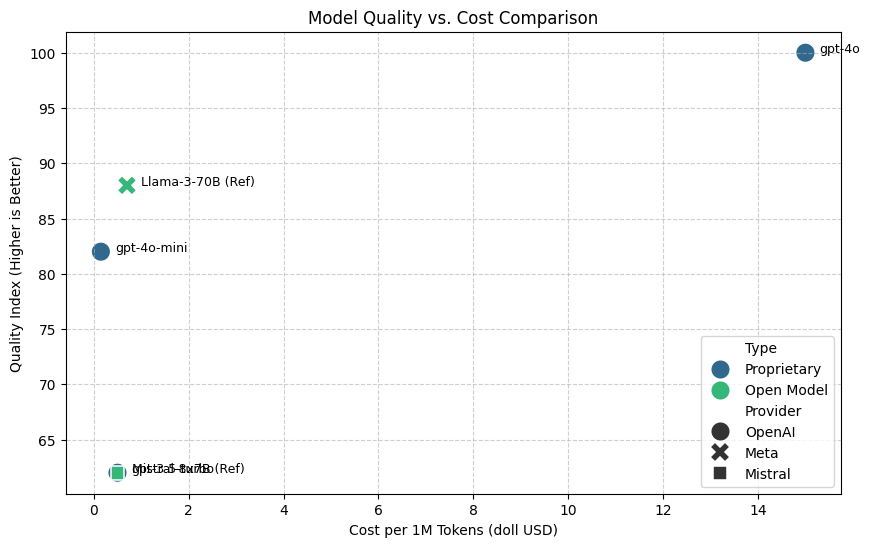

In [4]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=models_df,
    x="Cost_Per_1M_Tokens_USD",
    y="Quality_Index",
    hue="Type",
    style="Provider",
    s=200,
    palette="viridis"

)

for i in range(len(models_df)):
    plt.text(
        models_df["Cost_Per_1M_Tokens_USD"].iloc[i] + 0.3, 
        models_df["Quality_Index"].iloc[i], 
        models_df["Model"].iloc[i], 
        fontsize=9
    )

plt.title("Model Quality vs. Cost Comparison")
plt.xlabel("Cost per 1M Tokens (doll USD)")
plt.ylabel("Quality Index (Higher is Better)")
plt.grid(True , linestyle="--", alpha=0.6)
plt.show()

## Programmatic Model Testing & Benchmarking


In [ ]:
def test_model_response(model_name, prompt):

    import time
    start_time=time.time()

    try:
        response = client.chat.completions.create(
            model=model_name,
            messages=[
            {"role": "system", "content": "You are a concise AI assistant."},
            {"role": "user", "content": prompt},
            ],
            temperature=0.3,
            max_tokens=150,
        )
        duration=time.time() - start_time
        return{
            "model": model_name,
            "status":"Success",
            "output":response.choices[0].message.content,
            "latency_seconds":round(duration,3)

        }
    except: Eception as e:
        def test_model_response(model_name, prompt):

            start_time = time.time()

            try:
                response = client.chat.completions.create(
                    model=model_name,
                    messages=[
                        {"role": "system", "content": "You are a concise AI assistant."},
                        {"role": "user", "content": prompt},
                    ],
                    temperature=0.3,
                    max_tokens=150,
                )
                duration = time.time() - start_time
                return {
                    "model": model_name,
                    "status": "Success",
                    "output": response.choices[0].message.content,
                    "latency_seconds": round(duration, 3),
                }
            except Exception as e:
                return {
                    "model": model_name,
                    "status": "Error",
                    "output": str(e),
                    "latency_seconds": 0.0,
                }

    

    